In [1]:
Sys.unsetenv("PROJ_LIB")
Sys.unsetenv("GDAL_DATA")
library(dplyr)
library(sf)
library(ggplot2)
library(rnaturalearth)
library(rnaturalearthdata)
library(patchwork)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Linking to GEOS 3.14.1, GDAL 3.13.3, PROJ 9.9.0; sf_use_s2() is TRUE


Attaching package: ‘rnaturalearthdata’


The following object is masked from ‘package:rnaturalearth’:

    countries110




In [2]:
Sys.setenv(PROJ_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/proj")
Sys.setenv(GDAL_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/gdal")

In [ ]:
file.exists(file.path(Sys.getenv("PROJ_LIB"), "proj.db"))

[1] TRUE

In [5]:
nerrs_metaT=read.csv("../output/metaT_informed_NERRS_20260926_1.csv")

In [6]:
nerrs_allometry=read.csv("../output/allometry_NERRS_20260926_1.csv")

In [7]:
nerrs_nutrients=read.csv("../data/nerrs_data_cleaned.csv")

In [8]:
nerrs_metadata=read.csv("../data/nerrs_all_metadata.csv")

In [10]:
nerrs_merged=nerrs_metaT %>%
    dplyr::filter(index>50) %>% 
    dplyr::rename(c("metaT"="abund")) %>%
    dplyr::inner_join(nerrs_allometry%>%
                     dplyr::rename(c("allometry"="abund")),
                    by=c("DateTime","taxon","Site"))

In [11]:
corr_res = data.frame()
for (taxon_curr in (unique(nerrs_merged$taxon))) {
    for (site_curr in unique(nerrs_merged$Site)) {
        nerrs_merged_sub = nerrs_merged %>% dplyr::filter(taxon==taxon_curr) %>%
            dplyr::filter(Site==site_curr)
        corr_curr = cor.test(nerrs_merged_sub$metaT,nerrs_merged_sub$allometry,method="pearson")
        corr_res = corr_res %>% dplyr::bind_rows(data.frame(taxon=taxon_curr,
                                                 site=site_curr,
                                                 corr = corr_curr$estimate,
                                                 pval = corr_curr$p.value))
    }
}

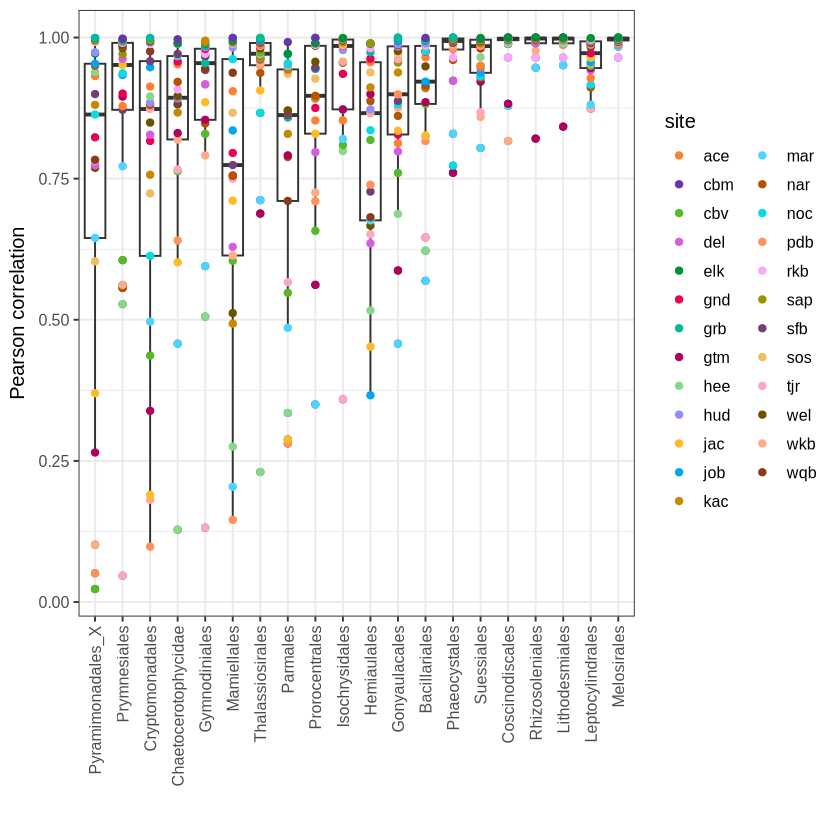

In [12]:
ggplot(corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr))+ 
    geom_boxplot(aes(x=factor(taxon,levels=unique(taxon)),group=taxon,y=corr))+ 
    geom_point(aes(x=factor(taxon,levels=unique(taxon)),color=site,group=site,y=corr))+ 
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Pearson correlation") + xlab("") + 
    scale_color_manual(values=c("#ff8030",
"#6836ab",
"#57b928",
"#d45de2",
"#009238",
"#e90057",
"#01bb99",
"#b0005f",
"#88d88c",
"#908fff",
"#fcbb27",
"#02a6eb",
"#c98800",
"#4ad4ff",
"#b75300",
"#08dbe2",
"#ff925c",
"#fca7ff",
"#979500",
"#733f76",
"#f2bd61",
"#ffa7bb",
"#6d5200",
"#ffab85",
"#883c1d",
"#9a5d4d"))

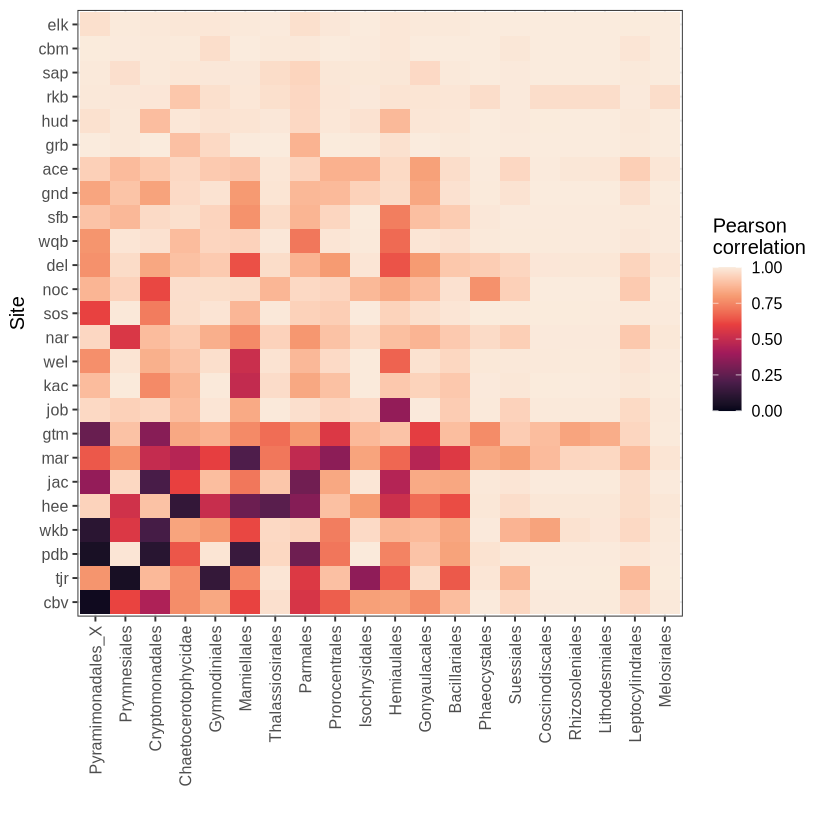

In [13]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

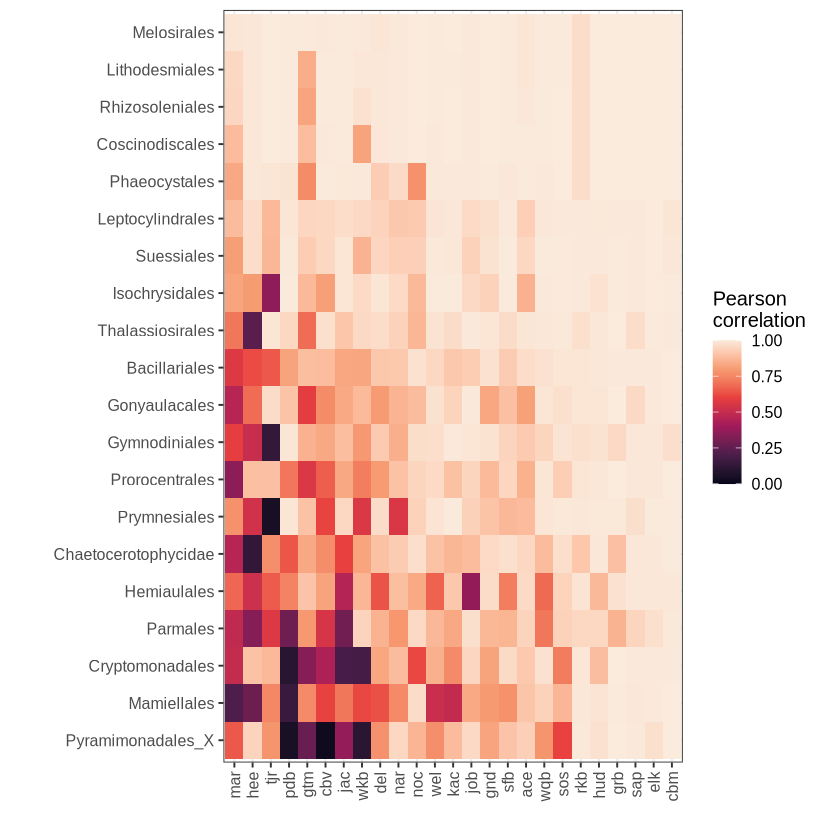

In [14]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)

summarize_corr_site = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(site) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

summarize_corr_taxon = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

rotate_tile = ggplot(for_tile)+ 
    geom_tile(aes(y=factor(taxon,levels=unique(summarize_corr_taxon$taxon)),
                  x=factor(site,levels=unique(summarize_corr_site$site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("") + xlab("")

rotate_tile

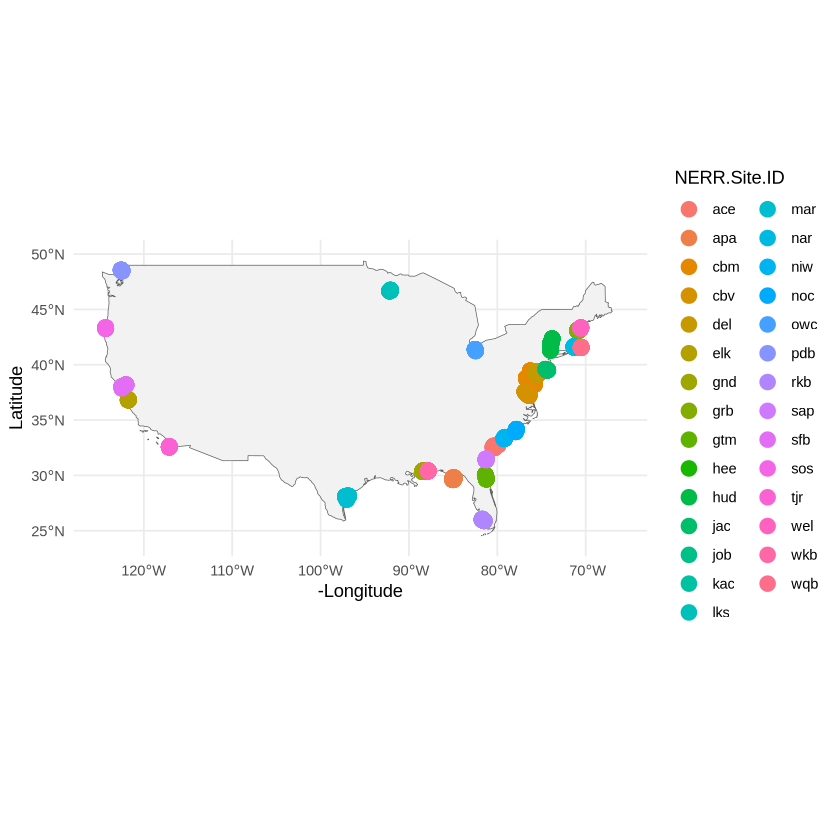

In [15]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_point(data = nerrs_metadata, aes(x = -Longitude, y = Latitude,col=NERR.Site.ID), size = 4) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50)) + # Zoom into mainland USA
  theme_minimal()

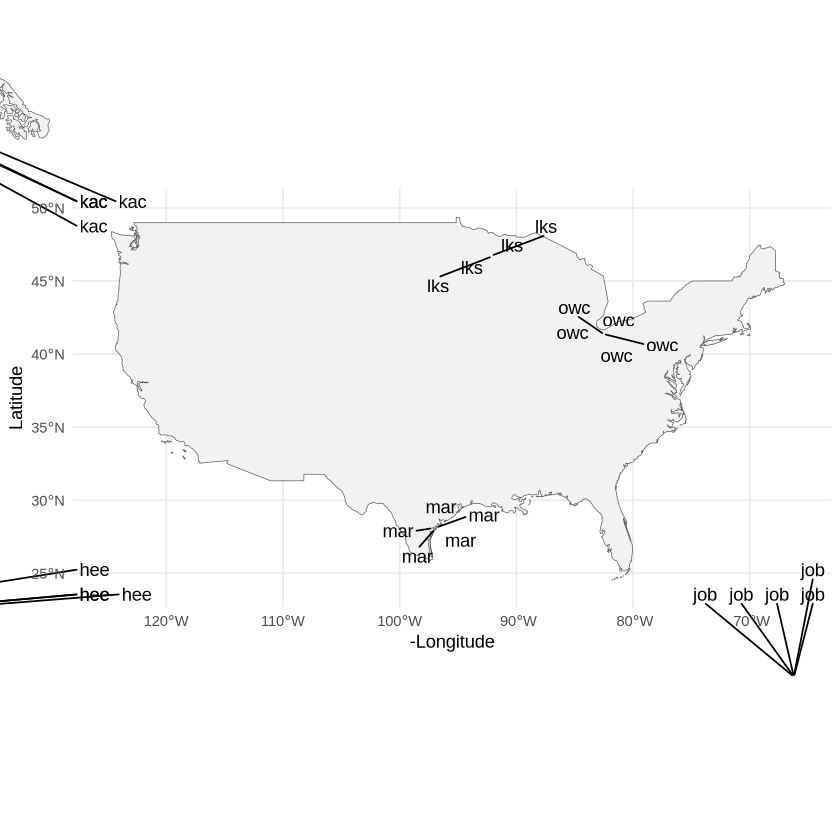

In [26]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::mutate(Latitude=round(Latitude,2),
                          Longitude=round(Longitude,2)) %>%
            dplyr::distinct(Latitude,Longitude,NERR.Site.ID), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID)) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_minimal()

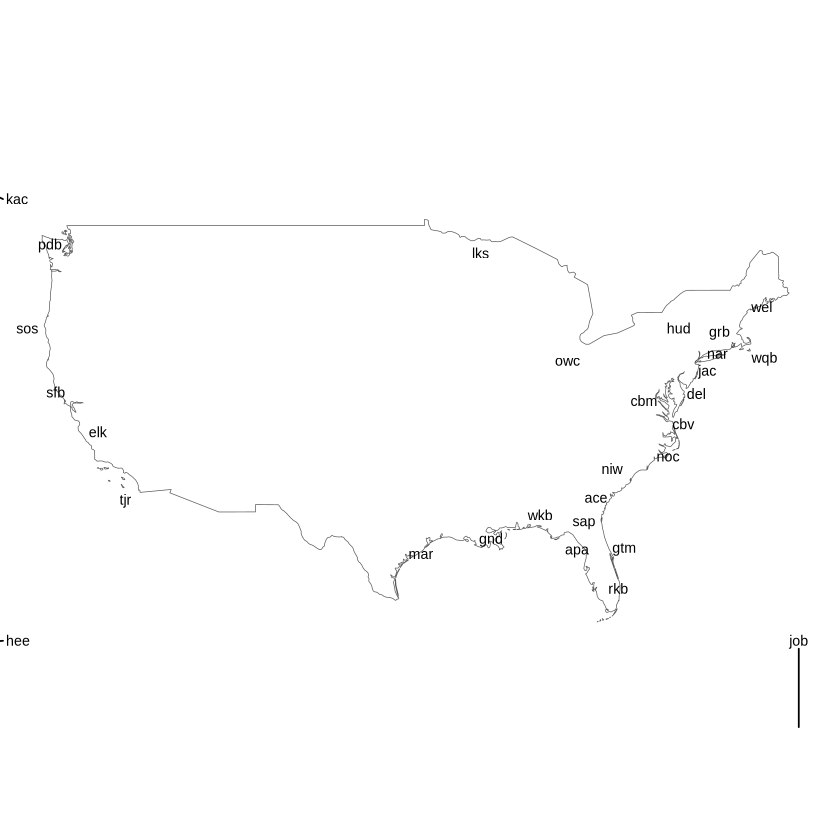

In [24]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

map_plt = ggplot() +
  geom_sf(data = usa, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),
    max.overlaps = Inf,size=3) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
map_plt

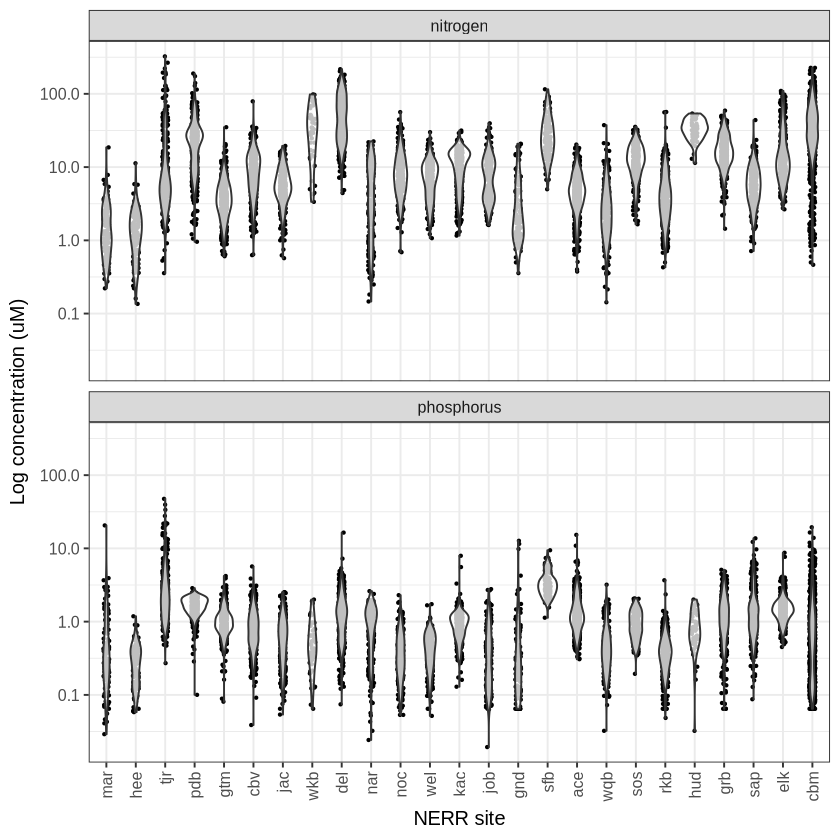

In [26]:
nutrient_box = ggplot(nerrs_nutrients %>%
       dplyr::filter(NERR.Site.ID %in% unique(for_tile$site)) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
       tidyr::pivot_longer(cols = starts_with("nitrogen")|starts_with("phosphorus"),
                           names_to = "species",
                           values_to = "uM")) + 
       geom_jitter(aes(x=factor(NERR.Site.ID,levels=unique(summarize_corr_site$site)),y=uM),
                   height=0,width=0.1,size=0.5) +
       geom_violin(aes(x=factor(NERR.Site.ID,levels=unique(summarize_corr_site$site)),y=uM),
                   alpha=0.75,fill="white") +
    facet_wrap(~species,nrow=2)+
    scale_y_log10()+ 
    theme_bw(base_size=12) + xlab("NERR site")+
    ylab("Log concentration (uM)") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))
nutrient_box

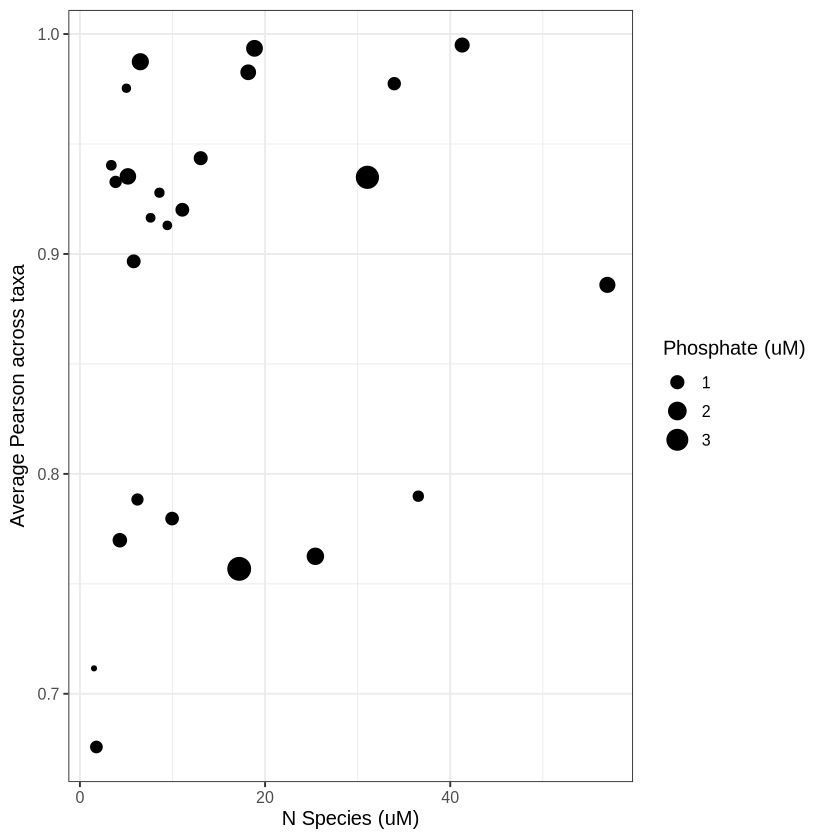

In [18]:
ggplot(nerrs_nutrients %>%
       dplyr::filter(NERR.Site.ID %in% unique(for_tile$site)) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
    dplyr::group_by(NERR.Site.ID) %>%
    dplyr::summarize(nitrogen=mean(nitrogen),phosphorus=mean(phosphorus)) %>%
    dplyr::left_join(summarize_corr_site,by=c("NERR.Site.ID"="site"))) + 
    geom_point(aes(x=nitrogen,y=avg_corr,size=phosphorus)) + 
    theme_bw(base_size=12) + 
    ylab("Average Pearson across taxa") + xlab("N Species (uM)") + 
    scale_size(name="Phosphate (uM)")

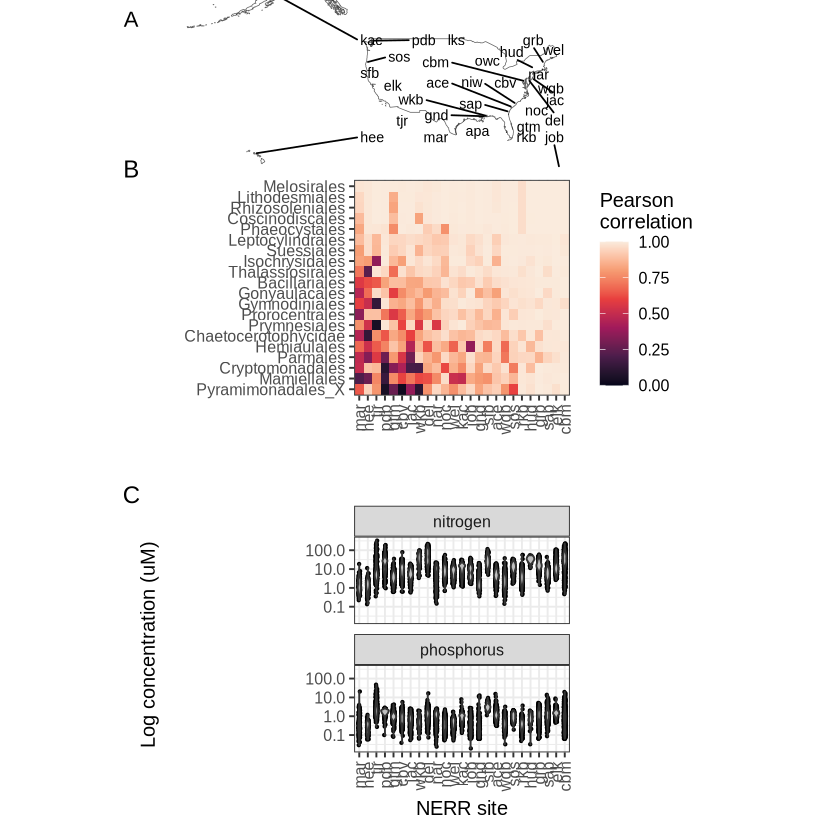

In [28]:
(map_plt/rotate_tile/nutrient_box)+plot_annotation(tag_levels = "A")
ggsave("../figures/figure_4_nutrients.pdf",width=10,height=12,units="in")

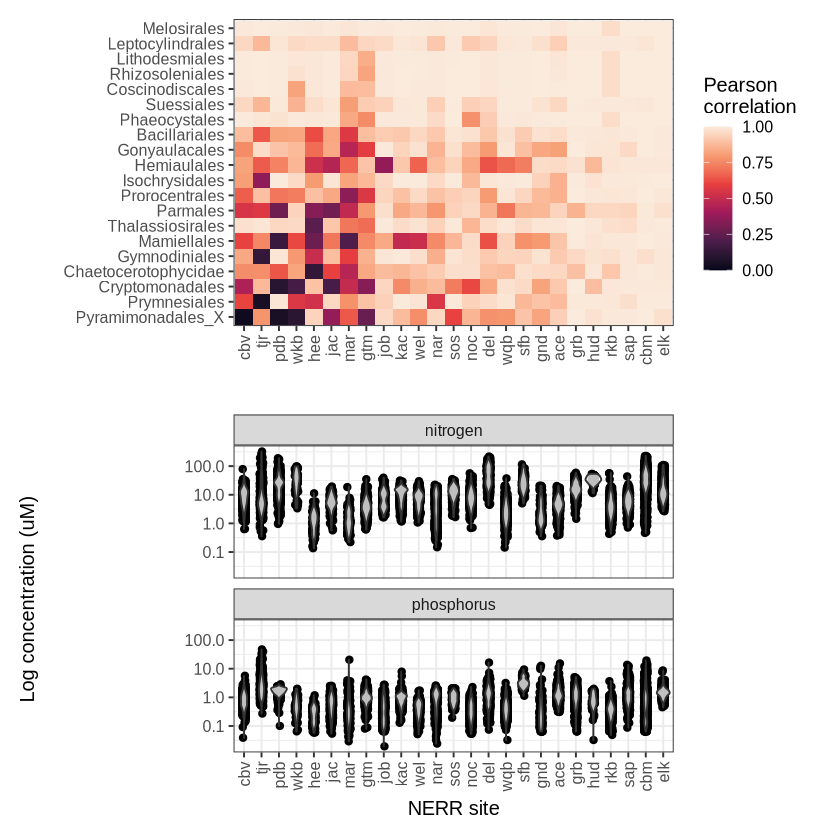

In [31]:
rotate_tile/nutrient_box

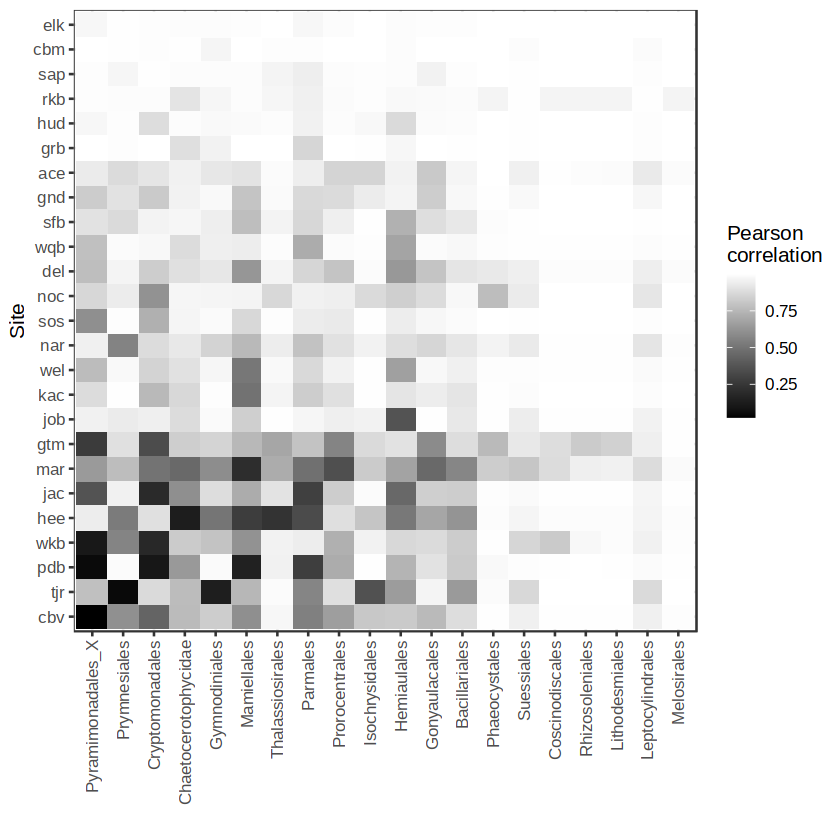

In [59]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_gradient(low="black",high="white",
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

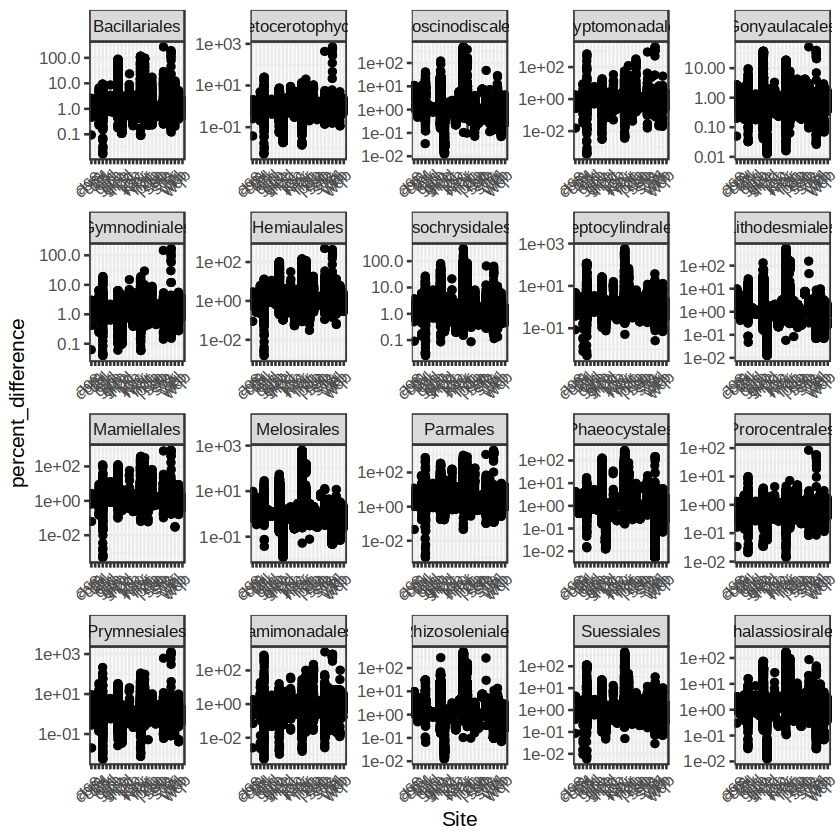

In [5]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=Site,y=percent_difference))+
    geom_jitter(aes(Site,y=percent_difference),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~taxon,scales="free") + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


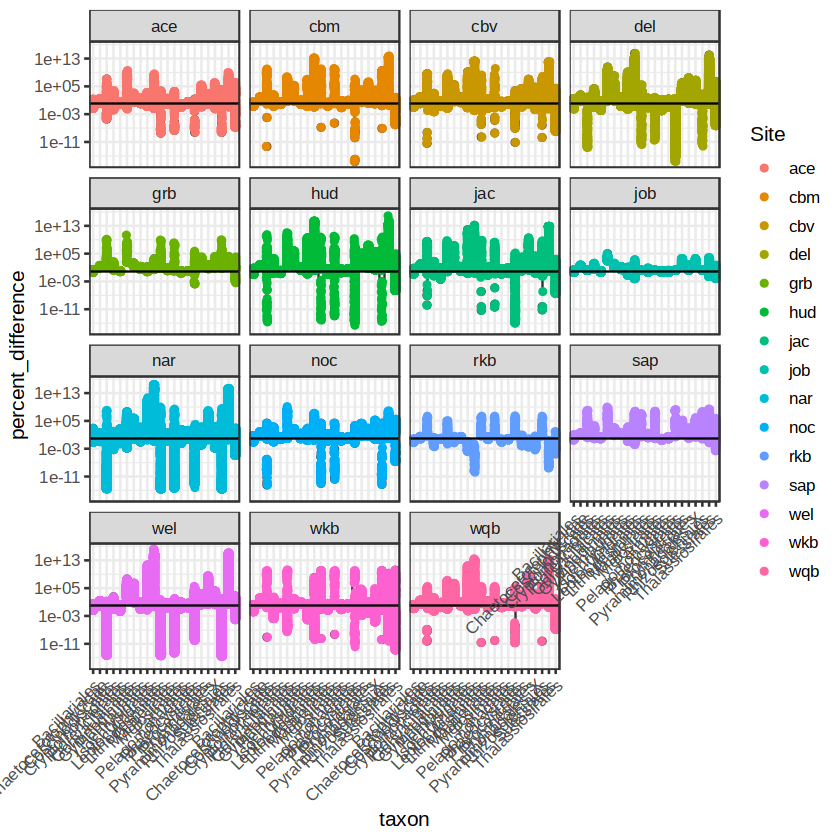

In [6]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~Site) + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


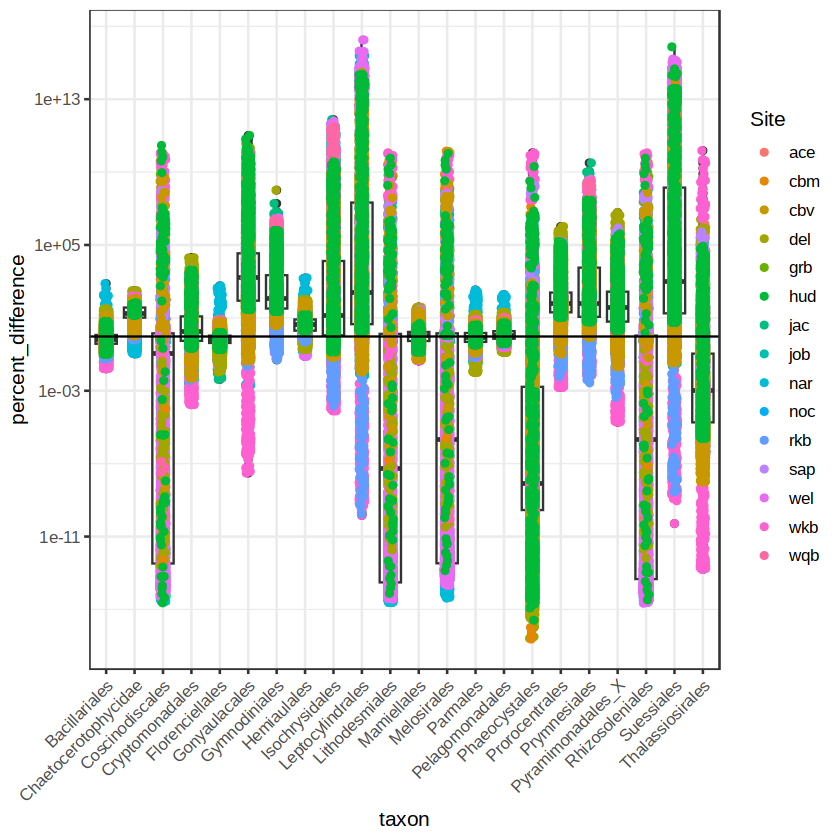

In [7]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

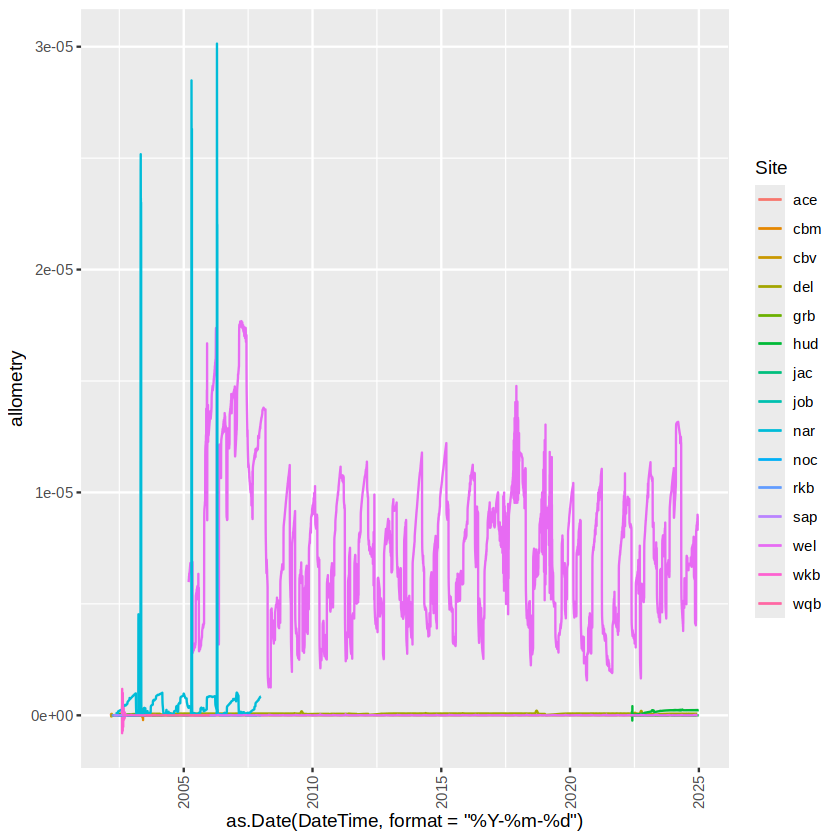

In [8]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Gonyaulacales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

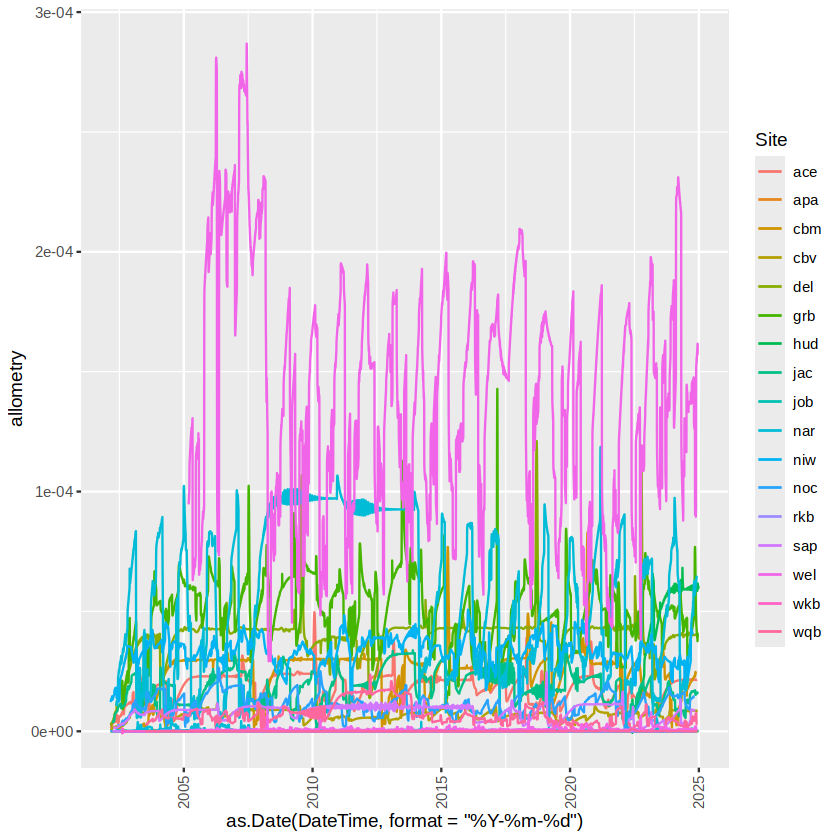

In [7]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Prorocentrales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

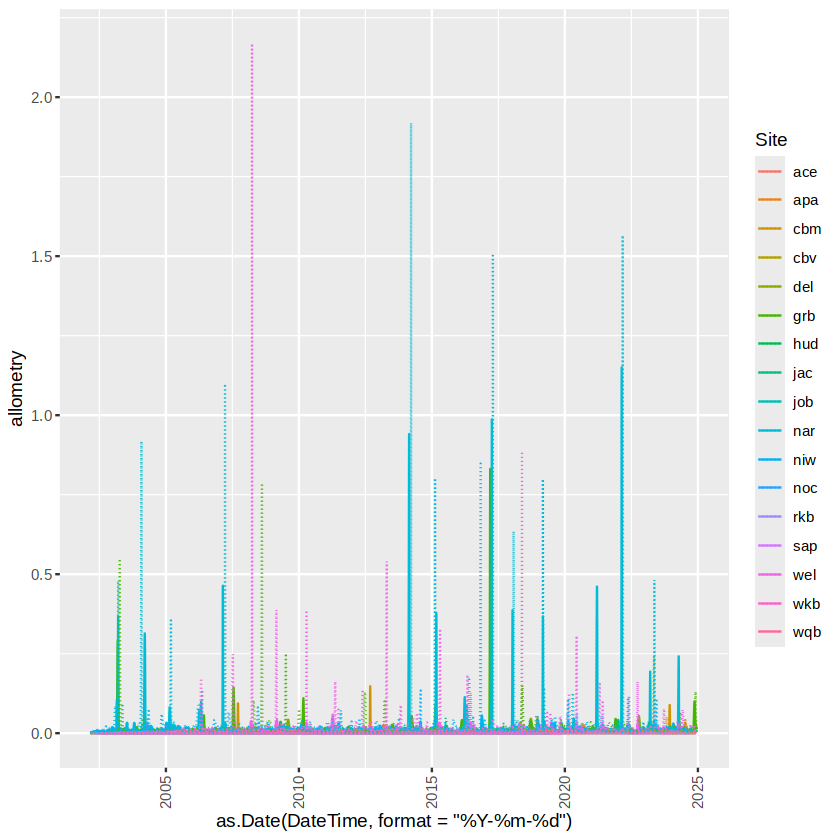

In [9]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Isochrysidales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site),linetype="dotted")+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

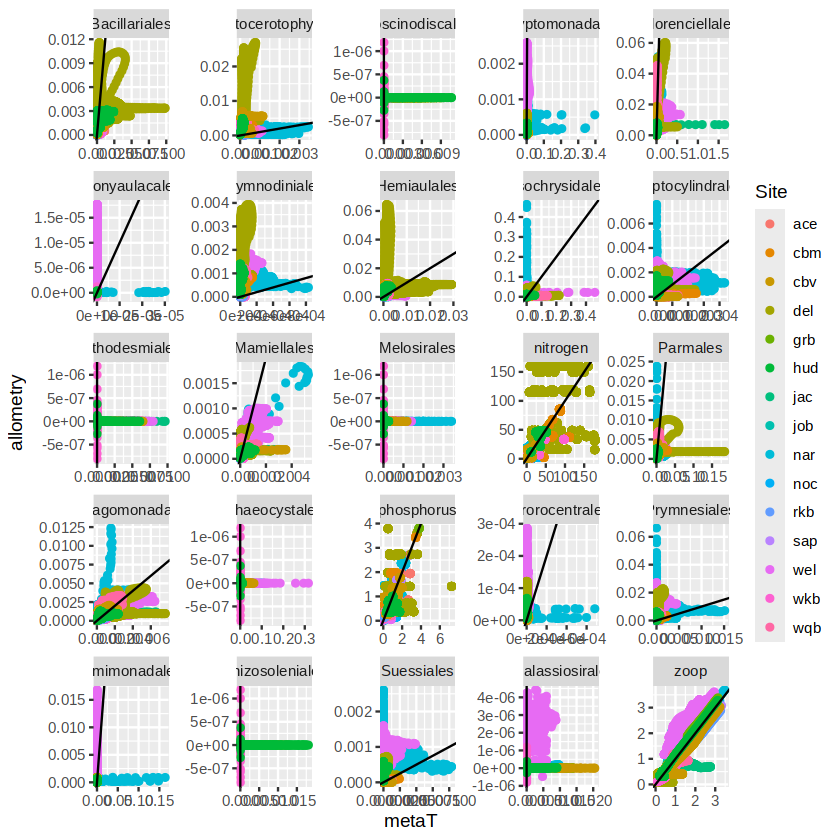

In [9]:
ggplot(nerrs_merged) + 
    geom_point(aes(x=metaT,y=allometry,color=Site))+
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free")

In [13]:
unique(nerrs_merged$Site)

[1] "ace" "wqb" "hud" "cbv" "wel" "noc" "cbm" "nar" "niw" "job" "jac" "rkb"
[13] "apa" "grb" "sap" "del" "wkb"